1. Import Library
Bagian ini memanggil library untuk pengolahan data, visualisasi, preprocessing, pemodelan, dan evaluasi.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

2. Memuat Dataset
Pastikan train.csv, test.csv, dan gender_submission.csv berada di folder kerja yang sama dengan notebook. Jika file berada di lokasi lain, sesuaikan alamat pada pd.read_csv().

In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
gender_submission = pd.read_csv("gender_submission.csv")

print("Ukuran train:", train.shape)
print("Ukuran test:", test.shape)
print("Ukuran gender_submission:", gender_submission.shape)

display(train.head())
display(test.head())
display(gender_submission.head())

Ukuran train: (891, 12)
Ukuran test: (418, 11)
Ukuran gender_submission: (418, 2)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


3. Memahami Struktur Data
Periksa nama kolom, tipe data, dan ringkasan statistik. Kolom Survived merupakan target yang akan diprediksi.

In [3]:
print("Informasi data train:")
train.info()

print("\nStatistik deskriptif:")
display(train.describe(include="all").T)

print("\nJumlah kelas target:")
display(train["Survived"].value_counts().rename(index={0: "Tidak selamat", 1: "Selamat"}))

Informasi data train:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Statistik deskriptif:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292



Jumlah kelas target:


Survived
Tidak selamat    549
Selamat          342
Name: count, dtype: int64

4. Exploratory Data Analysis (EDA)
Visualisasi berikut membantu melihat distribusi target, usia penumpang, dan hubungan jenis kelamin dengan tingkat keselamatan.

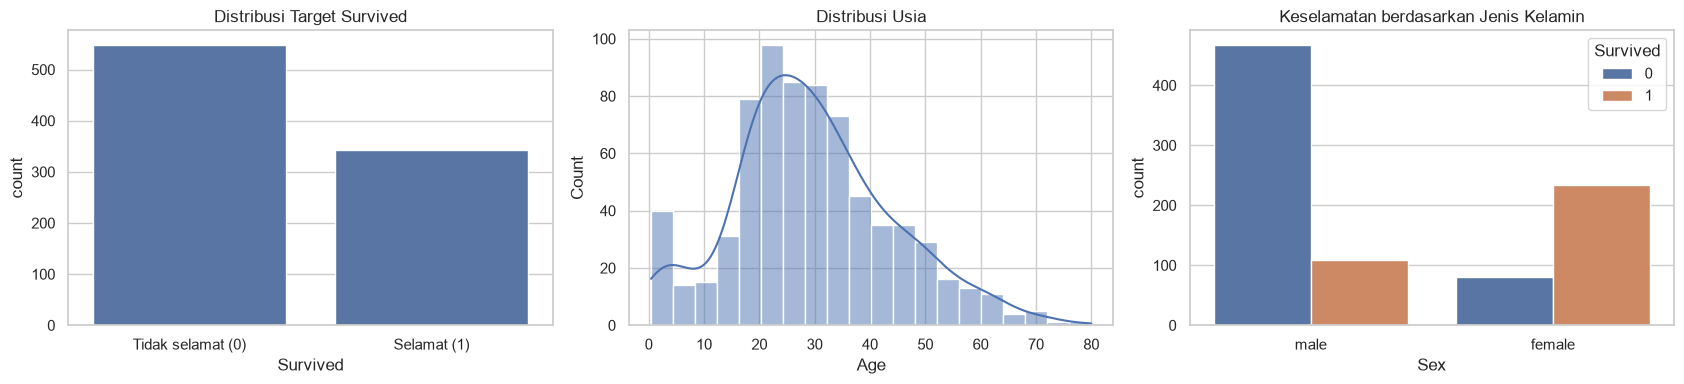

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

sns.countplot(data=train, x="Survived", ax=axes[0])
axes[0].set_title("Distribusi Target Survived")
axes[0].set_xticks([0, 1], ["Tidak selamat (0)", "Selamat (1)"])

sns.histplot(data=train, x="Age", kde=True, ax=axes[1])
axes[1].set_title("Distribusi Usia")

sns.countplot(data=train, x="Sex", hue="Survived", ax=axes[2])
axes[2].set_title("Keselamatan berdasarkan Jenis Kelamin")

plt.tight_layout()
plt.show()

5. Pemeriksaan Missing Value dan Data Duplikat
Nilai kosong perlu ditangani sebelum model dilatih. Pemeriksaan ini juga melihat apakah terdapat baris duplikat pada data train dan test.

In [5]:
print("Missing value pada train:")
display(train.isnull().sum().sort_values(ascending=False))

print("Missing value pada test:")
display(test.isnull().sum().sort_values(ascending=False))

print("Jumlah baris duplikat train:", train.duplicated().sum())
print("Jumlah baris duplikat test:", test.duplicated().sum())

Missing value pada train:


Cabin          687
Age            177
Embarked         2
PassengerId      0
Name             0
Pclass           0
Survived         0
Sex              0
Parch            0
SibSp            0
Fare             0
Ticket           0
dtype: int64

Missing value pada test:


Cabin          327
Age             86
Fare             1
Name             0
Pclass           0
PassengerId      0
Sex              0
Parch            0
SibSp            0
Ticket           0
Embarked         0
dtype: int64

Jumlah baris duplikat train: 0
Jumlah baris duplikat test: 0


6. Menentukan Fitur dan Target
Kolom Survived menjadi target. PassengerId, Name, Ticket, dan Cabin tidak digunakan dalam model dasar ini agar contoh tetap terfokus pada fitur demografis dan perjalanan. Kolom PassengerId tetap disimpan untuk mengidentifikasi hasil prediksi.

Fitur yang digunakan:
- Numerik: Pclass, Age, SibSp, Parch, Fare
- Kategorikal: Sex, Embarked
Preprocessing dilakukan melalui pipeline sehingga nilai kosong dan encoding dipelajari hanya dari data training pada setiap proses fitting.

In [6]:
target = "Survived"
feature_columns = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]

X = train[feature_columns].copy()
y = train[target].copy()
X_test = test[feature_columns].copy()

numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Sex", "Embarked"]

print("Jumlah fitur:", len(feature_columns))
print("Jumlah data train:", X.shape[0])
print("Jumlah data test:", X_test.shape[0])

Jumlah fitur: 7
Jumlah data train: 891
Jumlah data test: 418


7. Membagi Data Training dan Validasi
Data train dibagi menjadi 80% data training dan 20% data validasi. stratify=y menjaga proporsi kelas target pada kedua bagian agar pembagian lebih seimbang.

In [7]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Data training:", X_train.shape)
print("Data validasi:", X_valid.shape)

Data training: (712, 7)
Data validasi: (179, 7)


8. Preprocessing Data
- Fitur numerik: nilai kosong diisi menggunakan median.
- Fitur kategorikal: nilai kosong diisi menggunakan modus, lalu diubah menjadi angka dengan One-Hot Encoding.
- handle_unknown="ignore" membantu menangani kategori baru yang mungkin muncul pada data validasi atau test.
Seluruh preprocessing digabungkan dengan model dalam satu pipeline untuk menghindari data leakage.

In [8]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing berhasil disiapkan.")

Preprocessing berhasil disiapkan.


9. Membuat dan Melatih Model Random Forest
Random Forest merupakan algoritma ensemble yang menggabungkan banyak decision tree. Prediksi akhir ditentukan berdasarkan hasil voting dari pohon-pohon tersebut.

In [9]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)
print("Model berhasil dilatih.")

Model berhasil dilatih.


10. Evaluasi Model pada Data Validasi
Evaluasi dilakukan pada data validasi yang tidak digunakan untuk melatih model. Metrik yang ditampilkan adalah accuracy, precision, recall, dan F1-score.

In [10]:
y_pred = model.predict(X_valid)

accuracy = accuracy_score(y_valid, y_pred)
precision = precision_score(y_valid, y_pred, zero_division=0)
recall = recall_score(y_valid, y_pred, zero_division=0)
f1 = f1_score(y_valid, y_pred, zero_division=0)

metrics_df = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Nilai": [accuracy, precision, recall, f1]
})

display(metrics_df)
print("\nClassification Report:")
print(classification_report(
    y_valid,
    y_pred,
    target_names=["Tidak selamat", "Selamat"],
    zero_division=0
))

,Metrik,Nilai
0,Accuracy,0.804469
1,Precision,0.757576
2,Recall,0.724638
3,F1-Score,0.740741



Classification Report:
               precision    recall  f1-score   support

Tidak selamat       0.83      0.85      0.84       110
      Selamat       0.76      0.72      0.74        69

     accuracy                           0.80       179
    macro avg       0.79      0.79      0.79       179
 weighted avg       0.80      0.80      0.80       179



11. Confusion Matrix
Confusion matrix menunjukkan jumlah prediksi benar dan salah untuk setiap kelas. Baris menunjukkan kelas sebenarnya, sedangkan kolom menunjukkan kelas prediksi.

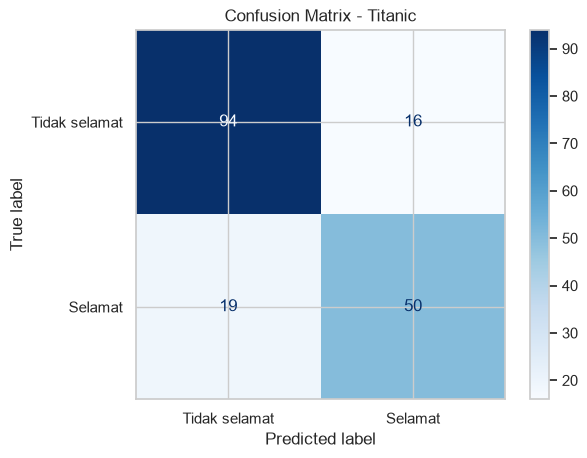

In [11]:
cm = confusion_matrix(y_valid, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Tidak selamat", "Selamat"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Titanic")
plt.show()

12. Melatih Ulang Model dengan Seluruh Data Train
Setelah evaluasi selesai, pipeline dilatih ulang menggunakan seluruh data dari train.csv. Langkah ini memanfaatkan semua data berlabel sebelum membuat prediksi untuk test.csv

In [12]:
final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        n_jobs=-1
    ))
])

final_model.fit(X, y)
print("Final model berhasil dilatih menggunakan seluruh data train.")

Final model berhasil dilatih menggunakan seluruh data train.


13. Prediksi Data Test
Model menghasilkan prediksi 0 atau 1 untuk setiap penumpang pada test.csv. Hasil digabungkan dengan PassengerId agar sesuai dengan format kompetisi Kaggle.

In [13]:
test_predictions = final_model.predict(X_test)

submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": test_predictions.astype(int)
})

display(submission.head())
print("Jumlah hasil prediksi:", len(submission))
print("Distribusi prediksi:")
display(submission["Survived"].value_counts().sort_index())

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,1
4,896,1


Jumlah hasil prediksi: 418
Distribusi prediksi:


Survived
0    248
1    170
Name: count, dtype: int64

14. Menyimpan File Submission
File submission.csv disimpan dengan dua kolom yang diminta oleh kompetisi Titanic Kaggle: PassengerId dan Survived. File ini dapat diunggah ke halaman submission kompetisi.

In [14]:
submission.to_csv("submission.csv", index=False)
print("File submission.csv berhasil disimpan.")

# Memastikan format file sesuai
saved_submission = pd.read_csv("submission.csv")
display(saved_submission.head())
print("Kolom submission:", saved_submission.columns.tolist())

File submission.csv berhasil disimpan.


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,1
4,896,1


Kolom submission: ['PassengerId', 'Survived']


15. Membandingkan dengan gender_submission.csv (Opsional)
gender_submission.csv adalah contoh prediksi/baseline yang disediakan Kaggle, bukan label aktual untuk data test. Karena itu, perbandingan di bawah hanya melihat berapa banyak prediksi model yang sama dengan baseline tersebut. Nilai ini bukan accuracy model yang sebenarnya.

In [15]:
baseline = gender_submission[["PassengerId", "Survived"]].copy()

comparison = submission.merge(
    baseline,
    on="PassengerId",
    how="inner",
    suffixes=("_model", "_baseline")
)

same_prediction = (
    comparison["Survived_model"] == comparison["Survived_baseline"]
).mean()

print(f"Jumlah baris yang dibandingkan: {len(comparison)}")
print(f"Persentase prediksi model yang sama dengan baseline: {same_prediction:.2%}")
display(comparison.head())

Jumlah baris yang dibandingkan: 418
Persentase prediksi model yang sama dengan baseline: 81.34%


,PassengerId,Survived_model,Survived_baseline
0,892,0,0
1,893,0,1
2,894,0,0
3,895,1,0
4,896,1,1


16. Kesimpulan
Pada praktikum ini, dilakukan proses klasifikasi biner menggunakan dataset Titanic dari Kaggle. Target yang diprediksi adalah Survived, dengan nilai 0 untuk penumpang yang tidak selamat dan 1 untuk penumpang yang selamat.

Tahapan yang dilakukan meliputi pemuatan data, eksplorasi, pemeriksaan missing value dan duplikasi, preprocessing fitur numerik dan kategorikal, pembagian data training dan validasi, pelatihan model Random Forest, serta evaluasi menggunakan accuracy, precision, recall, F1-score, dan confusion matrix.

Setelah evaluasi, model dilatih kembali menggunakan seluruh data train dan digunakan untuk memprediksi data test. Hasil prediksi disimpan dalam file submission.csv. Kinerja model dinilai berdasarkan data validasi, bukan berdasarkan gender_submission.csv, karena file tersebut hanya merupakan contoh submission dari Kaggle.

Catatan penulisan laporan: masukkan nilai metrik yang benar-benar muncul setelah notebook dijalankan. Hasil dapat berubah jika parameter atau pembagian data diubah.